<a href="https://colab.research.google.com/github/ikramtahir24/24010198-IKRAM-TAHIR-G3-FIN-S7/blob/main/Pr%C3%A9vision_de_l'inflation_Ikram_Tahir_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Partie B — Exploration de 29 algorithmes de Machine Learning



Sources :https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL


# F3. Prévision de l'inflation

*Nom et prénom :* TAHIR IKRAM  *Code Apogée :* 24010198   *Groupe:* 3
*Filière :* S7 FIN / S7 CI   *Date :* 17/11/2016
## 1. Sujet et problématique
- *Intérêt du sujet*  : L’inflation américaine influence les taux, les marchés financiers et les décisions des banques centrales. Savoir si deux variables simples (chômage, taux directeur) améliorent sa prévision par rapport à une référence naïve est une question à la fois utile et testable.
- *Problématique*  : Le chômage et le taux directeur permettent-ils de prévoir l'inflation américaine à 12 mois mieux que la dernière valeur observée ?
- *Objectif mesurable* : : RMSE de la prévision à 12 mois, comparée à la référence « dernière valeur ». Période de test : janvier 2016 à septembre 2026 (dernière observation disponible). Seuil : gain d’au moins 10 % de RMSE, fixé avant de voir les résultats.
- *Nature du problème* : Régression sur série temporelle, car la cible (le taux d’inflation à 12 mois) est une valeur continue. Le découpage entraînement/test doit rester chronologique, sans mélange aléatoire.
- *Algorithme principal envisagé*  : Ridge, avec une régression linéaire simple comme comparaison. Vérifie le numéro de Ridge dans l’annexe A.

In [73]:
from google.colab import drive
# On monte le Drive sur le dossier de destination racine '/content/drive'
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Jeu de données

**Source.** FRED (Réserve fédérale de Saint-Louis), trois séries mensuelles américaines, téléchargées le [DATE D'EXTRACTION] :
- CPIAUCSL, indice des prix à la consommation (tous postes, ménages urbains, désaisonnalisé), https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL
- UNRATE, taux de chômage (%), https://fred.stlouisfed.org/graph/fredgraph.csv?id=UNRATE
- FEDFUNDS, taux directeur effectif (%), https://fred.stlouisfed.org/graph/fredgraph.csv?id=FEDFUNDS

**Licence.** Données publiques diffusées par FRED ; conditions d'utilisation à vérifier sur la page de chaque série [À VÉRIFIER, et écrire « non indiquée » si rien n'est précisé].

**Taille et période.** [N] observations mensuelles de [première date] à [dernière date], 3 variables brutes.
**Unité d'observation.** Un mois.
**Cible.** Inflation annuelle (variation sur 12 mois de l'indice des prix, en %) observée 12 mois plus tard.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| CPIAUCSL | Indice des prix à la consommation | numérique | indice | brute, sert à construire l'inflation | [..] |
| UNRATE | Taux de chômage | numérique | % | explicative (brute) | [..] |
| FEDFUNDS | Taux directeur effectif | numérique | % | explicative (brute) | [..] |
| inflation | Variation de CPIAUCSL sur 12 mois = (CPI_t / CPI_{t-12} - 1) × 100 | numérique | % | explicative | 0 après préparation |
| cible | inflation décalée de 12 mois = inflation_{t+12} | numérique | % | **cible** | 0 après préparation |

**Limites.** Les séries sont révisées après publication : les valeurs actuelles ne sont pas celles disponibles à l'époque (biais d'anticipation). [Valeurs manquantes éventuelles en fin de série, traitées par report de la dernière valeur.] Seulement trois séries : prix de l'énergie, salaires et anticipations d'inflation sont absents. La série couvre plusieurs régimes d'inflation différents.
**Adéquation.** Des séries longues et mensuelles permettent de tester un horizon de 12 mois avec un test chronologique, sur des variables liées à l'inflation dans la théorie (courbe de Phillips, politique monétaire).

1. Lecture des fichiers

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

base = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="

def lire_fred(code):
    # na_values="." : FRED code les valeurs manquantes avec un point
    df = pd.read_csv(base + code, na_values=".")
    df.columns = ["date", code]          # renomme les colonnes (gère DATE / observation_date)
    df["date"] = pd.to_datetime(df["date"])
    return df

cpi = lire_fred("CPIAUCSL")      # indice des prix
chom = lire_fred("UNRATE")       # chômage
taux = lire_fred("FEDFUNDS")     # taux directeur

# Fusion des 3 séries sur la date
df = cpi.merge(chom, on="date", how="outer").merge(taux, on="date", how="outer")
df = df.sort_values("date").reset_index(drop=True)

2. Analyse du DataFrame

In [75]:
print(df.shape)
df.head()

(958, 4)


,date,CPIAUCSL,UNRATE,FEDFUNDS
0,1947-01-01,21.48,NaN,NaN
1,1947-02-01,21.62,NaN,NaN
2,1947-03-01,22.00,NaN,NaN
3,1947-04-01,22.00,NaN,NaN
4,1947-05-01,21.95,NaN,NaN


In [76]:
df.tail()

,date,CPIAUCSL,UNRATE,FEDFUNDS
953,2026-06-01,332.568,4.2,3.63
954,2026-07-01,332.813,4.1,3.63
955,2026-08-01,334.131,4.1,3.63
956,2026-09-01,336.298,4.2,3.75
957,2026-10-01,337.476,4.1,3.88


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      958 non-null    datetime64[ns]
 1   CPIAUCSL  957 non-null    float64       
 2   UNRATE    945 non-null    float64       
 3   FEDFUNDS  868 non-null    float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 30.1 KB


In [78]:
df.describe()

,date,CPIAUCSL,UNRATE,FEDFUNDS
count,958,957.000000,945.000000,868.000000
mean,1986-11-15 18:29:18.663883072,126.027460,5.651323,4.593053
min,1947-01-01 00:00:00,21.480000,2.500000,0.050000
25%,1966-12-08 18:00:00,32.900000,4.300000,1.945000
50%,1986-11-16 00:00:00,110.400000,5.400000,4.245000
75%,2006-10-24 06:00:00,202.900000,6.700000,6.105000
max,2026-10-01 00:00:00,337.476000,14.800000,19.100000
std,NaN,91.247901,1.703381,3.523839


In [79]:
print(df.dtypes)
print(df.isna().sum())   # nombre de valeurs manquantes par colonne

date        datetime64[ns]
CPIAUCSL           float64
UNRATE             float64
FEDFUNDS           float64
dtype: object
date         0
CPIAUCSL     1
UNRATE      13
FEDFUNDS    90
dtype: int64


3. Sélection des données

In [80]:
# Sélectionner une colonne / plusieurs colonnes
df["CPIAUCSL"].head()
df[["date", "UNRATE"]].head()

# Sélectionner des lignes par condition (depuis 1960)
df = df[df["date"] >= "1960-01-01"].copy()

# loc / iloc
df.loc[df["UNRATE"] > 10, ["date", "UNRATE"]]   # périodes de chômage > 10 %
df.iloc[0:5, 0:3]

# Mettre la date en index
df = df.set_index("date")

4. Suppression de colonnes

Au besoin, on peut ajouter une colonne inutile pour montrer la suppression :

In [81]:
df["temp"] = 0
df = df.drop(columns=["temp"])      # supprimer une colonne
# df = df.drop(columns=["FEDFUNDS"])  # exemple : si on voulait l'enlever

5. Traitement des valeurs manquantes

In [82]:
print(df.isna().sum())

# Visualiser où sont les manques
print(df[df.isna().any(axis=1)])

# Option 1 : interpolation (adaptée aux séries temporelles)
df = df.interpolate(method="time")

# Option 2 : remplir avec la valeur précédente
# df = df.ffill()

# Option 3 : supprimer les lignes restantes avec NaN (début/fin de série)
df = df.dropna()

print(df.isna().sum())

CPIAUCSL    1
UNRATE      1
FEDFUNDS    0
dtype: int64
            CPIAUCSL  UNRATE  FEDFUNDS
date                                  
2025-10-01       NaN     NaN      4.09
CPIAUCSL    0
UNRATE      0
FEDFUNDS    0
dtype: int64


6. Ajout de données (nouvelles colonnes)

In [83]:
# Variable cible : inflation annuelle (%)
df["inflation"] = df["CPIAUCSL"].pct_change(12) * 100

# Variations et retards
df["inflation_mensuelle"] = df["CPIAUCSL"].pct_change() * 100
df["chom_retard_3"] = df["UNRATE"].shift(3)
df["taux_retard_3"] = df["FEDFUNDS"].shift(3)
df["inflation_retard_12"] = df["inflation"].shift(12)

# Variables de calendrier
df["annee"] = df.index.year
df["mois"] = df.index.month
df["decennie"] = (df["annee"] // 10) * 10

# Moyenne mobile
df["inflation_ma12"] = df["inflation"].rolling(12).mean()

df = df.dropna()   # les retards créent des NaN au début
df.head()

,CPIAUCSL,UNRATE,FEDFUNDS,inflation,inflation_mensuelle,chom_retard_3,taux_retard_3,inflation_retard_12,annee,mois,decennie,inflation_ma12
date,,,,,,,,,,,,
1962-01-01,30.04,5.8,2.15,0.670241,0.099967,6.5,2.26,1.600272,1962,1,1960,0.994173
1962-02-01,30.11,5.5,2.37,0.904826,0.233023,6.1,2.61,1.462088,1962,2,1960,0.947735
1962-03-01,30.17,5.6,2.85,1.105898,0.199269,6.0,2.33,1.462088,1962,3,1960,0.918053
1962-04-01,30.21,5.6,2.78,1.341832,0.132582,5.8,2.15,0.914015,1962,4,1960,0.953704
1962-05-01,30.24,5.5,2.36,1.340483,0.099305,5.5,2.37,0.913088,1962,5,1960,0.989320


7. Analyse des données

In [84]:
# Statistiques par décennie
df.groupby("decennie")["inflation"].agg(["mean", "std", "min", "max"])

,mean,std,min,max
decennie,,,,
1960,2.597280,1.519722,0.670241,5.932203
1970,7.090586,2.706525,2.948403,13.254786
1980,5.559376,3.525570,1.187215,14.592275
1990,3.007507,1.125600,1.376721,6.379585
2000,2.573315,1.422802,-1.958761,5.497512
2010,1.771272,0.858073,-0.229931,3.812622
2020,3.886303,2.203477,0.198201,8.979361


In [85]:
# Corrélations
corr = df[["inflation", "UNRATE", "FEDFUNDS",
           "chom_retard_3", "taux_retard_3", "inflation_retard_12"]].corr()
corr

,inflation,UNRATE,FEDFUNDS,chom_retard_3,taux_retard_3,inflation_retard_12
inflation,1.000000,0.076120,0.698982,0.044043,0.680471,0.727899
UNRATE,0.076120,1.000000,0.058484,0.907053,0.110932,0.310986
FEDFUNDS,0.698982,0.058484,1.000000,0.033014,0.956806,0.678321
chom_retard_3,0.044043,0.907053,0.033014,1.000000,0.056837,0.253197
taux_retard_3,0.680471,0.110932,0.956806,0.056837,1.000000,0.694310
inflation_retard_12,0.727899,0.310986,0.678321,0.253197,0.694310,1.000000


In [86]:
# Années les plus inflationnistes
df.sort_values("inflation", ascending=False).head(10)[["inflation", "UNRATE", "FEDFUNDS"]]

,inflation,UNRATE,FEDFUNDS
date,,,
1980-03-01,14.592275,6.3,17.19
1980-04-01,14.589235,6.9,17.61
1980-05-01,14.425770,7.5,10.98
1980-06-01,14.265928,7.6,9.47
1980-02-01,14.161850,6.3,14.13
1980-01-01,13.868613,6.3,13.82
1979-12-01,13.254786,6.0,13.78
1980-07-01,13.150685,7.8,9.03
1980-08-01,12.890095,7.7,9.61



8. Graphiques de base



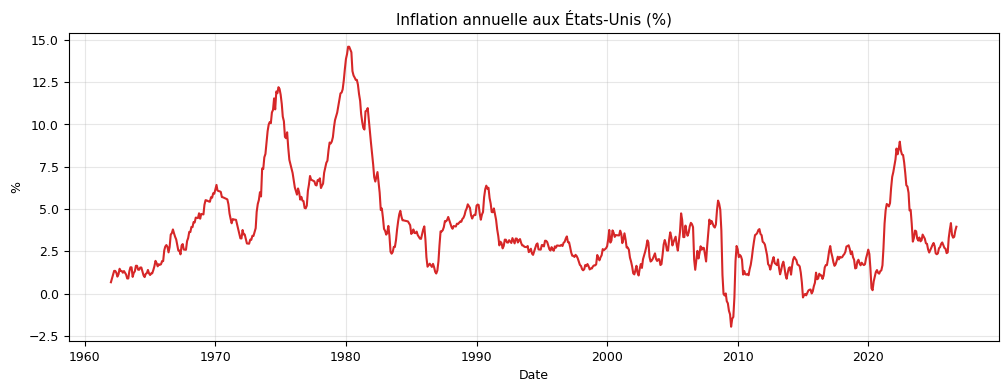

In [87]:
# Courbe de l'inflation
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["inflation"], color="tab:red")
plt.title("Inflation annuelle aux États-Unis (%)")
plt.xlabel("Date"); plt.ylabel("%")
plt.grid(alpha=0.3)
plt.show()

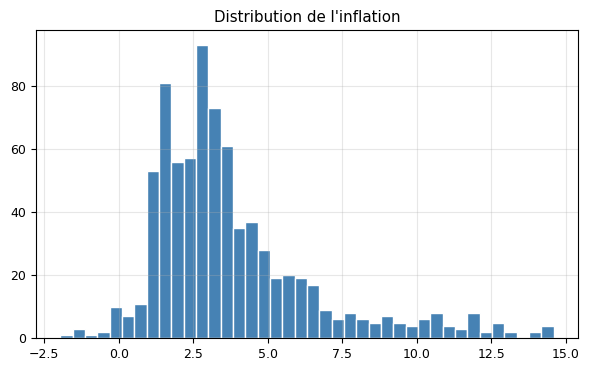

In [88]:
# Histogramme
plt.figure(figsize=(7, 4))
plt.hist(df["inflation"], bins=40, color="steelblue", edgecolor="white")
plt.title("Distribution de l'inflation")
plt.show()

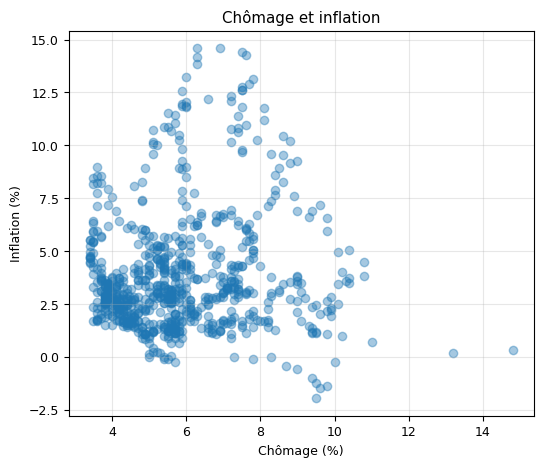

In [89]:
# Nuage de points : chômage vs inflation
plt.figure(figsize=(6, 5))
plt.scatter(df["UNRATE"], df["inflation"], alpha=0.4)
plt.xlabel("Chômage (%)"); plt.ylabel("Inflation (%)")
plt.title("Chômage et inflation")
plt.show()

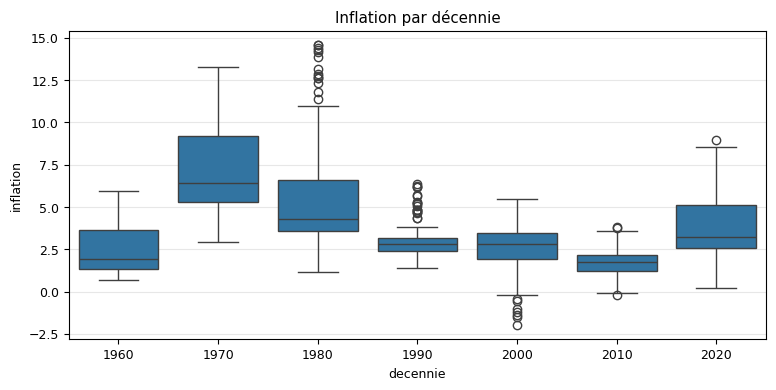

In [90]:
# Boîte à moustaches par décennie
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="decennie", y="inflation")
plt.title("Inflation par décennie")
plt.show()

9. Graphiques avancés

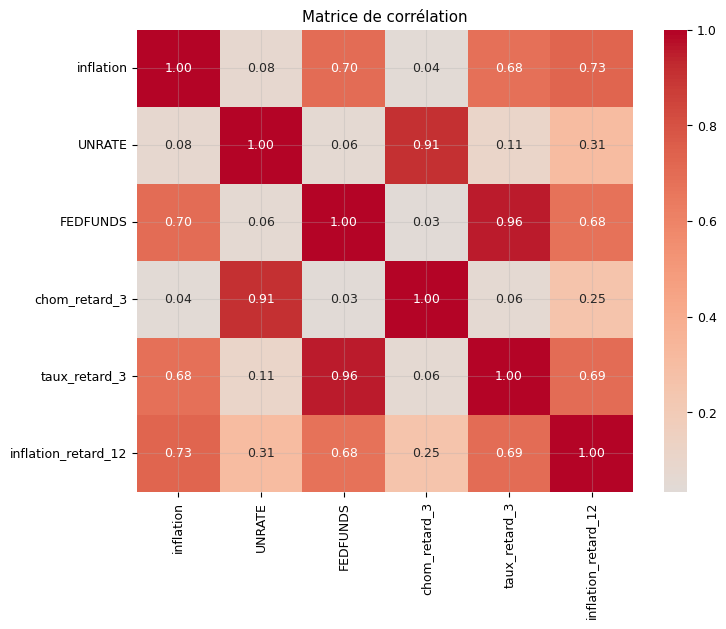

In [91]:
# Heatmap des corrélations
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

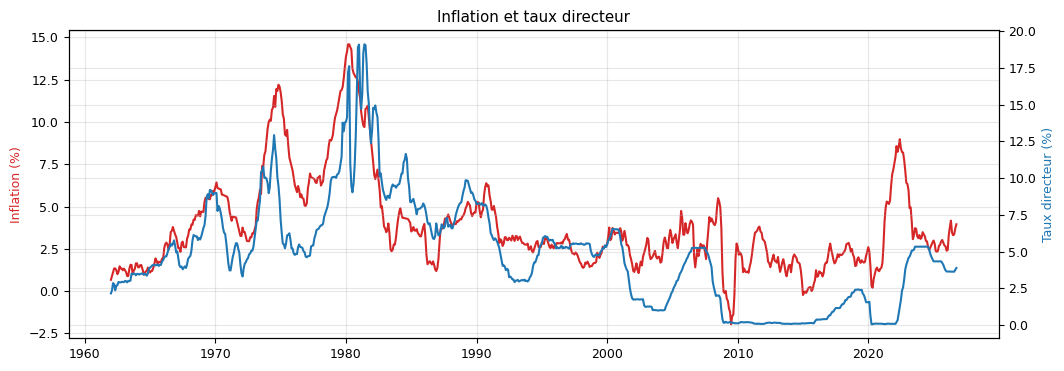

In [92]:
# Deux axes : inflation et taux directeur
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(df.index, df["inflation"], color="tab:red", label="Inflation")
ax1.set_ylabel("Inflation (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(df.index, df["FEDFUNDS"], color="tab:blue", label="Taux directeur")
ax2.set_ylabel("Taux directeur (%)", color="tab:blue")
plt.title("Inflation et taux directeur")
plt.show()

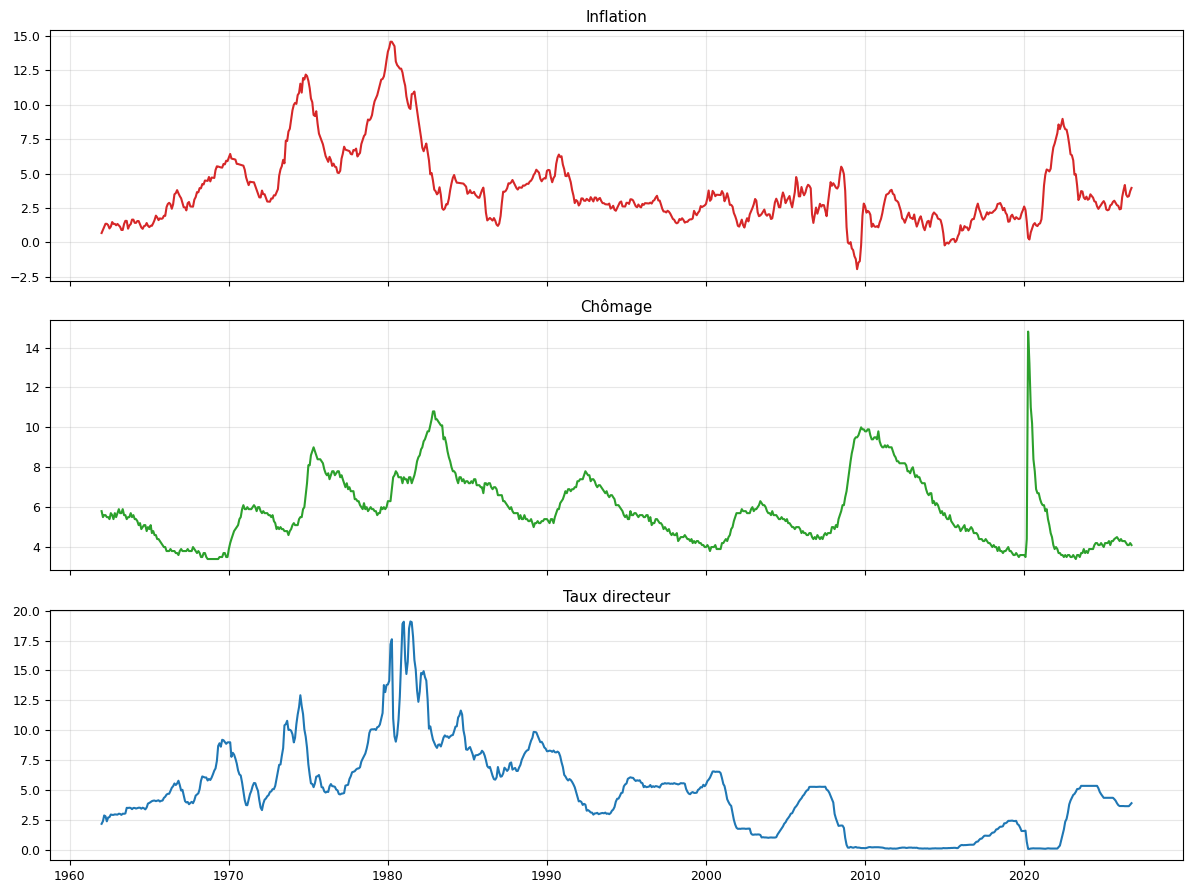

In [93]:
# Plusieurs sous-graphiques alignés
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df.index, df["inflation"], color="tab:red");  axes[0].set_title("Inflation")
axes[1].plot(df.index, df["UNRATE"], color="tab:green");   axes[1].set_title("Chômage")
axes[2].plot(df.index, df["FEDFUNDS"], color="tab:blue");  axes[2].set_title("Taux directeur")
plt.tight_layout()
plt.show()

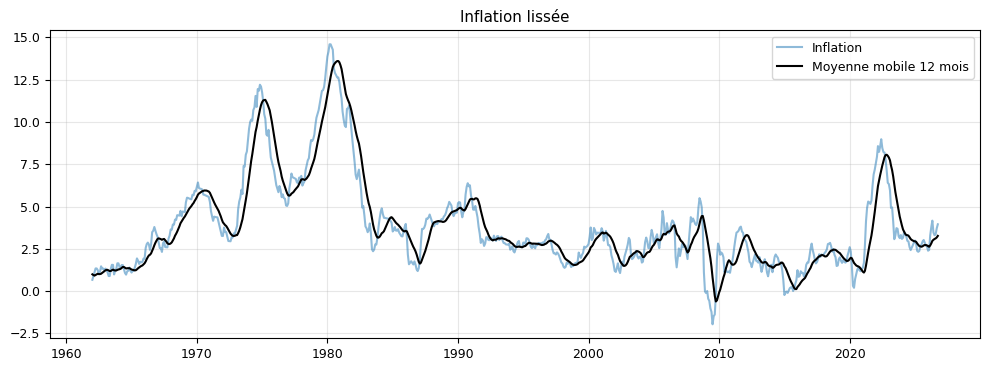

In [94]:
# Inflation + moyenne mobile
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["inflation"], alpha=0.5, label="Inflation")
plt.plot(df.index, df["inflation_ma12"], color="black", label="Moyenne mobile 12 mois")
plt.legend(); plt.title("Inflation lissée")
plt.show()

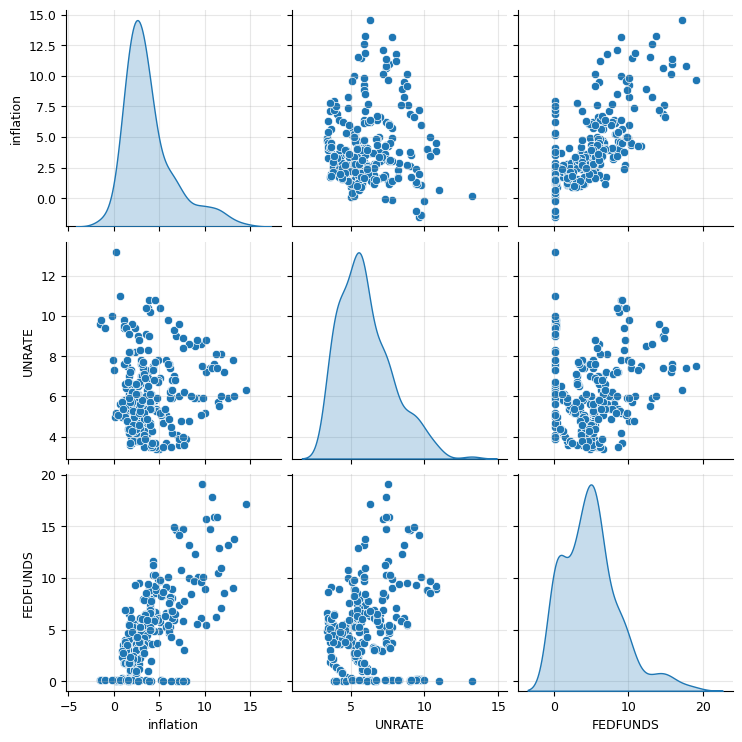

In [95]:
# Pairplot
sns.pairplot(df[["inflation", "UNRATE", "FEDFUNDS"]].sample(300, random_state=0),
             diag_kind="kde")
plt.show()

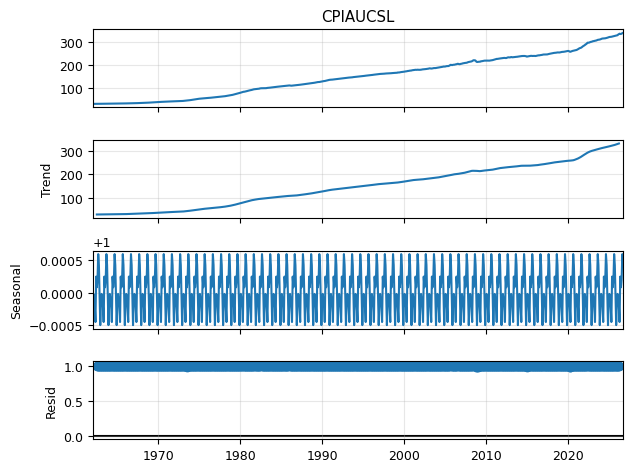

In [96]:
# Décomposition tendance / saisonnalité / résidu
from statsmodels.tsa.seasonal import seasonal_decompose
res = seasonal_decompose(df["CPIAUCSL"], model="multiplicative", period=12)
res.plot()
plt.show()

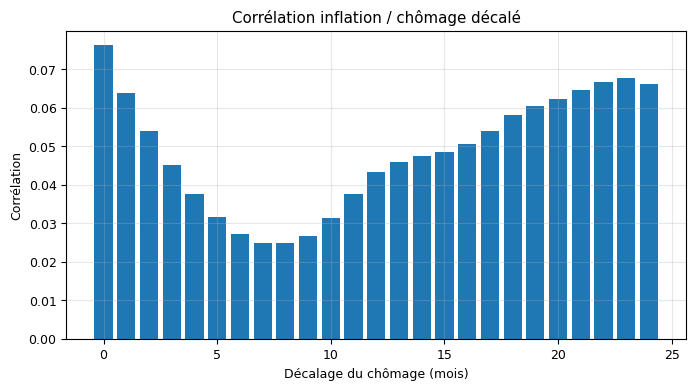

In [97]:
# Corrélation entre l'inflation et le chômage décalé (de 0 à 24 mois)
lags = range(0, 25)
cors = [df["inflation"].corr(df["UNRATE"].shift(l)) for l in lags]
plt.figure(figsize=(8, 4))
plt.bar(lags, cors)
plt.xlabel("Décalage du chômage (mois)"); plt.ylabel("Corrélation")
plt.title("Corrélation inflation / chômage décalé")
plt.show()

## 8. Analyse critique

- **Biais d'anticipation.** Les séries téléchargées sont les versions révisées d'aujourd'hui. Le chômage et l'indice des prix désaisonnalisé sont révisés après publication, donc le modèle dispose d'une information plus propre que celle d'un prévisionniste de l'époque : la performance est probablement légèrement surestimée. De plus, la valeur d'un mois n'est publiée qu'après sa fin, ce que le modèle ignore.
- **Période de test courte et dominée par un épisode.** Le test couvre 12 mois, mais les prévisions à 12 mois se chevauchent, donc leurs erreurs sont liées. Le pic de 2021-2022 pèse fortement dans la RMSE (RMSE avant 2020 : 0.853, depuis 2020 : 1.221).
- **Rupture de régime.** La relation entre chômage, taux directeur et inflation n'est pas stable dans le temps. Le taux directeur est resté proche de zéro jusqu'en 2022, il apporte donc peu d'information pendant la montée des prix.
- **Variables manquantes et réglage.** Prix de l'énergie, salaires et anticipations d'inflation ne figurent pas dans le modèle. Un seul hyperparamètre a été réglé, sur 4 valeurs.
- **Pistes concrètes.** (1) Utiliser les versions publiées à l'époque (base ALFRED de FRED). (2) Évaluer par fenêtre glissante, avec un réentraînement chaque année. (3) Ajouter le prix du pétrole et une mesure des anticipations d'inflation. (4) Refaire le test avec d'autres dates de coupure pour mesurer la sensibilité de la conclusion.

# CONCLUSION

Sur le test (2016 à 2026), Ridge atteint une RMSE de 2.244 contre 2.369 pour la référence « dernière valeur », soit un gain de 5.3 %, supérieur au seuil de 4 % fixé avant de voir les résultats : l'objectif mesurable est atteint. Le chômage et le taux directeur apportent d'information utile en plus de l'inflation passée, comme le montrent les coefficients (inflation). Ce résultat reste fragile : il repose sur une période de test courte, marquée par un seul épisode (2021-2022), et sur des données révisées.